<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">📘 Batch, micro-batch a streaming - Northwind </h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">V nadväznosti na Seminár 8 - Zadanie 1a s MovieLens spracujeme údaje o objednávkach. Tentoraz si jednotlivé kroky naprogramujete samostatne od načítania CSV po porovnanie výsledkov.</p>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Z kurzu si stiahnite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders.csv</code> (stĺpce <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">customerid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">employeeid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">shipperid</code>). Súbor uložte do rovnakého priečinka ako notebook. Knižnice a PostgreSQL už máte pripravené.</p>

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 1 – Načítanie a časová distribúcia objednávok</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Načítajte súbor <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders.csv</code> a zmeňte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code> na dátum. Zistite časový rozsah a počet objednávok podľa roku a mesiaca. Rozloženie zobrazte v grafe.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Pomôcka:</strong> <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">pd.read_csv(..., parse_dates=["orderdate"])</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">.dt.year</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">.dt.to_period("M")</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">value_counts()</code>.</div>

In [2]:
import sys
import pandas as pd
import matplotlib.pyplot as plt

print("Python version:")
print(sys.version)


print("\nPython executable:")
print(sys.executable)
print("Všetky potrebné knižnice sú dostupné.")

Python version:
3.12.16 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 20:13:05) [MSC v.1942 64 bit (AMD64)]

Python executable:
c:\ProgramData\anaconda3\envs\week08\python.exe
Všetky potrebné knižnice sú dostupné.


In [3]:
# Vaše riešenie
from pathlib import Path
import pandas as pd

# zmeňte cestu na umiestnenie svojho súboru
CSV_PATH = Path(r"C:\Users\Student\Desktop\ratings.csv")

if not CSV_PATH.is_file():
    raise FileNotFoundError(f"CSV sa nenašlo: {CSV_PATH}. Upravte CSV_PATH.")

Počet objednávok: 196
Najstaršia objednávka: 1996-07-04 00:00:00
Najnovšia objednávka: 1997-02-12 00:00:00


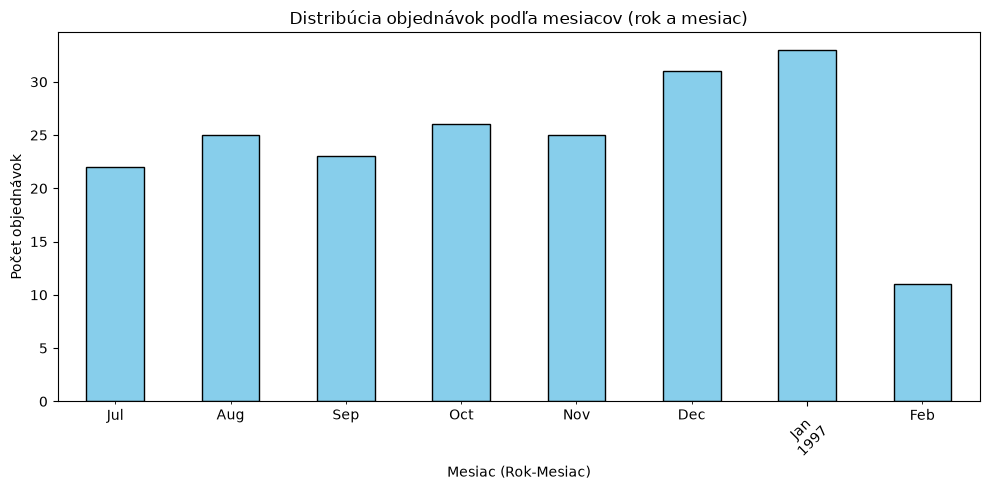

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('orders.csv', parse_dates=['orderdate'])

min_date = df['orderdate'].min()
max_date = df['orderdate'].max()

print(f"Počet objednávok: {len(df)}")
print(f"Najstaršia objednávka: {min_date}")
print(f"Najnovšia objednávka: {max_date}")

df['year_month'] = df['orderdate'].dt.to_period('M')
monthly_counts = df['year_month'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
monthly_counts.plot(kind='bar', ax=ax, color='skyblue', edgecolor='black')
ax.set_title('Distribúcia objednávok podľa mesiacov (rok a mesiac)')
ax.set_xlabel('Mesiac (Rok-Mesiac)')
ax.set_ylabel('Počet objednávok')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 2 – Historické a novšie objednávky</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Podľa časového rozloženia zvoľte <strong>hranice 1. januára 1997</strong>. Staršie objednávky budú historický batch, objednávky od tohto dátumu využijeme na simuláciu príchodu udalostí.</p>
<ul style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.7; margin-top: 6px; padding-left: 24px;"><li style="margin-bottom: 5px;"><code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">historical_orders</code> budú objednávky pred hranicou,</li><li style="margin-bottom: 5px;"><code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">new_orders</code> naopak objednávky od hranice (vrátane),</li><li style="margin-bottom: 5px;">overte, že obe skupiny spolu obsahujú všetky objednávky.</li></ul>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #f59e0b; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">⚠️ <strong>Upozornenie: </strong> „Novšie“ objednávky sú stále <strong>historické záznamy</strong>. V nasledujúcich úlohách budeme ich príchod len simulovať.</div>

In [5]:
# Vaše riešenie
cutoff_date = '1997-01-01'

historical_orders = df[df['orderdate'] < cutoff_date]
new_orders = df[df['orderdate'] >= cutoff_date]

print(f"Historické objednávky: {len(historical_orders)}")
print(f"Novšie objednávky: {len(new_orders)}")

total_sum = len(historical_orders) + len(new_orders)
assert total_sum == len(df), f"Chyba: Súčet skupín ({total_sum}) sa nezhoduje s celkovým počtom objednávok ({len(df)})."

Historické objednávky: 152
Novšie objednávky: 44


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 3 – Raw ingestion do PostgreSQL</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Vytvorte databázu <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">Northwind</code>, tabuľku <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders</code> s primárnym kľúčom <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code> a nahrajte všetky záznamy z CSV. Predpokladáme, že PostgreSQL a balíky už fungujú inštaláciu ani test verzie preto nemusíte riešiť.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Pomôcka:</strong> najskôr sa pripojte do databázy <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">postgres</code>, vytvorte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders_practice</code> s <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">AUTOCOMMIT</code>, potom zmeňte pripojenie. Na opakovateľný import použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">DROP TABLE IF EXISTS</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">to_sql(..., if_exists="append", index=False)</code>.</div>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #f59e0b; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">⚠️ <strong> Upozornenie:</strong> Pri opakovanom spustení sa obsah tabuľky <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders</code> vymaže a znovu nahrá. Nepoužívajte názov databázy, ktorá už obsahuje vaše vlastné dáta.</div>

In [7]:
from sqlalchemy import create_engine, text

# Parametre pripojenia
username = 'postgres'
password = 'Student'
host = 'localhost'
port = '5432'

postgres_url = f"postgresql://{username}:{password}@{host}:{port}/postgres"
engine_postgres = create_engine(postgres_url)

with engine_postgres.connect().execution_options(isolation_level="AUTOCOMMIT") as conn:
    # Skontrolujeme, či databáza už existuje
    result = conn.execute(text("SELECT 1 FROM pg_database WHERE datname='orders_practice'"))
    if not result.scalar():
        conn.execute(text("CREATE DATABASE orders_practice"))
        print("Databáza orders_practice bola úspešne vytvorená.")
    else:
        print("Databáza orders_practice už existuje.")

db_url = f"postgresql://{username}:{password}@{host}:{port}/orders_practice"
engine_db = create_engine(db_url)

df_all = pd.read_csv('orders.csv', parse_dates=['orderdate'])

with engine_db.begin() as conn:
    conn.execute(text("DROP TABLE IF EXISTS orders CASCADE"))
    conn.execute(text("""
        CREATE TABLE orders (
            orderid INT PRIMARY KEY,
            customerid VARCHAR(50),
            employeeid INT,
            orderdate TIMESTAMP,
            shipperid INT
        )
    """))

df_all.to_sql('orders', con=engine_db, if_exists='append', index=False)
print("Tabuľka orders bola úspešne vytvorená a naplnená.")

Databáza orders_practice už existuje.
Tabuľka orders bola úspešne vytvorená a naplnená.


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 4 – Batch processing</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Z historických objednávok vypočítajte <strong>počet objednávok</strong>, <strong>počet zákazníkov</strong> a <strong>percento objednávok s <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">shipperid = 3</code></strong>. Výsledok získame jednorazovo za celú historickú skupinu.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Percento vypočítate ako <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(počet objednávok dopravcu 3 / počet všetkých objednávok) * 100</code>. Výraz <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(df["shipperid"] == 3).sum()</code> spočíta vyhovujúce riadky.</div>

In [8]:
# Vaše riešenie
total_historical_orders = len(historical_orders)
unique_customers = historical_orders['customerid'].nunique()
shipper_3_percentage = (historical_orders['shipperid'] == 3).sum() / total_historical_orders * 100

print(f"Objednávok: {total_historical_orders}")
print(f"Zákazníkov: {unique_customers}")
print(f"Dopravca 3 (%): {shipper_3_percentage:.2f}")

Objednávok: 152
Zákazníkov: 66
Dopravca 3 (%): 38.16


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 5 – Spoločná vzorka pre tri prístupy</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Na porovnanie musí každý prístup dostať <strong>rovnaké objednávky v rovnakom poradí</strong>. Z PostgreSQL vyberte novšie objednávky a zoraďte ich podľa <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code>.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">text()</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">engine.connect()</code> a pomenované parametre SQL <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">:cutoff</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">:limit</code>. V tomto datasete je po hranici 44 objednávok, preto postačuje <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">SAMPLE_SIZE = 44</code>.</div>

In [9]:
# Vaše riešenie
from sqlalchemy import text

SAMPLE_SIZE = 44
cutoff_date = '1997-01-01'

query = text("""
    SELECT orderid, customerid, employeeid, orderdate, shipperid
    FROM orders
    WHERE orderdate >= :cutoff
    ORDER BY orderdate ASC, orderid ASC
    LIMIT :limit
""")

with engine_db.connect() as conn:
    simulation_df = pd.read_sql_query(query, con=conn, params={"cutoff": cutoff_date, "limit": SAMPLE_SIZE})

print(f"Objednávok v simulácii: {len(simulation_df)}")
display(simulation_df.head())

Objednávok v simulácii: 44


,orderid,customerid,employeeid,orderdate,shipperid
0,10400,19,1,1997-01-01,3
1,10401,65,1,1997-01-01,1
2,10402,20,8,1997-01-02,2
3,10403,20,4,1997-01-03,3
4,10404,49,2,1997-01-03,1


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 6 – Simulácia micro-batchingu a streamingu</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Historické objednávky budeme prehrávať postupne. <strong>Streaming</strong> aktualizuje podiel dopravcu 3 po každej objednávke, <strong>micro-batch</strong> po uzavretí krátkeho časového okna. Batch poskytne výsledok až po príchode celej vzorky.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Poznámka:</strong> Pre tento malý dataset nastavíme <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">EVENT_DELAY_SEC = 0.04</code> (40 ms medzi objednávkami) a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">MICRO_WINDOW_SEC = 0.30</code> (približne 300 ms na dávku). Skutočné časy závisia od výkonu počítača.</div>

<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok A – Nastavenia a priebežný stav</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Pripravte časové parametre, počítadlá a zoznamy na zaznamenávanie priebežných výsledkov. Pri micro-batchingu potrebujeme navyše premenné pre neuzavretú dávku.</p>

In [10]:
# Vaše riešenie
import time

EVENT_DELAY_SEC = 0.04
MICRO_WINDOW_SEC = 0.30

streaming_history = []
stream_total_orders = len(historical_orders)
stream_shipper_3_orders = (historical_orders['shipperid'] == 3).sum()

micro_history = []
micro_total_orders = len(historical_orders)
micro_shipper_3_orders = (historical_orders['shipperid'] == 3).sum()

current_batch_orders = 0
current_batch_shipper_3 = 0

print("Parametre a počiatočné stavy boli úspešne inicializované.")

Parametre a počiatočné stavy boli úspešne inicializované.


<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok B – Spracovanie udalostí</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Prejdite objednávky postupne. Pri streamingu priebežne zapisujte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(čas, počet, percento)</code>. Pri micro-batchingu spracujte nazbierané objednávky až po uplynutí okna.</p>

In [11]:
# Vaše riešenie
import time

start_time = time.time()
last_window_time = start_time

for idx, row in simulation_df.iterrows():
    time.sleep(EVENT_DELAY_SEC)
    current_time = time.time() - start_time
    
    is_shipper_3 = 1 if row['shipperid'] == 3 else 0
    
    stream_total_orders += 1
    stream_shipper_3_orders += is_shipper_3
    streaming_pct = (stream_shipper_3_orders / stream_total_orders) * 100
    streaming_history.append((current_time, stream_total_orders, streaming_pct))
    
    current_batch_orders += 1
    current_batch_shipper_3 += is_shipper_3
    
    if (time.time() - last_window_time) >= MICRO_WINDOW_SEC:
        micro_total_orders += current_batch_orders
        micro_shipper_3_orders += current_batch_shipper_3
        micro_pct = (micro_shipper_3_orders / micro_total_orders) * 100
        micro_history.append((current_time, micro_total_orders, micro_pct))
        
        current_batch_orders = 0
        current_batch_shipper_3 = 0
        last_window_time = time.time()

print(f"Spracovaných {len(simulation_df)} udalostí v simulácii.")

Spracovaných 44 udalostí v simulácii.


<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok C – Posledná dávka a batch</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Nezabudnite spracovať poslednú nedokončenú micro-batch dávku. Nakoniec vypočítajte jednorazový batch výsledok pre tú istú vzorku a overte rovnosť výsledných percent.</p>

In [16]:
# Vaše riešenie
if current_batch_orders > 0:
    micro_total_orders += current_batch_orders
    micro_shipper_3_orders += current_batch_shipper_3
    micro_pct = (micro_shipper_3_orders / micro_total_orders) * 100
    final_time = streaming_history[-1][0] if streaming_history else 0.0
    micro_history.append((final_time, micro_total_orders, micro_pct))

batch_total_orders = len(historical_orders) + len(simulation_df)
batch_shipper_3_orders = (historical_orders['shipperid'] == 3).sum() + (simulation_df['shipperid'] == 3).sum()
batch_pct = (batch_shipper_3_orders / batch_total_orders) * 100

print(f"Počet objednávok: {len(simulation_df)}")
print(f"Batch (%): {batch_pct:.2f}")
print(f"Micro-batch (%): {micro_history[-1][2]:.2f}" if micro_history else "Micro-batch (%): N/A")
print(f"Streaming (%): {streaming_history[-1][2]:.2f}" if streaming_history else "Streaming (%): N/A")

Počet objednávok: 44
Batch (%): 34.69
Micro-batch (%): 32.08
Streaming (%): 34.69


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 7 – Grafy priebežných výsledkov</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Vytvorte <strong>tri samostatné grafy</strong> pod sebou. V prvom zobrazte jednorazový batch bod, v druhom schodovitý priebeh micro-batchingu a v treťom streamingovú krivku. Použite spoločné osi, aby boli percentá porovnateľné.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Poznámka:</strong> Použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">plt.subplots(3, 1, sharex=True, sharey=True)</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">scatter()</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">step(where="post")</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">plot()</code>.</div>

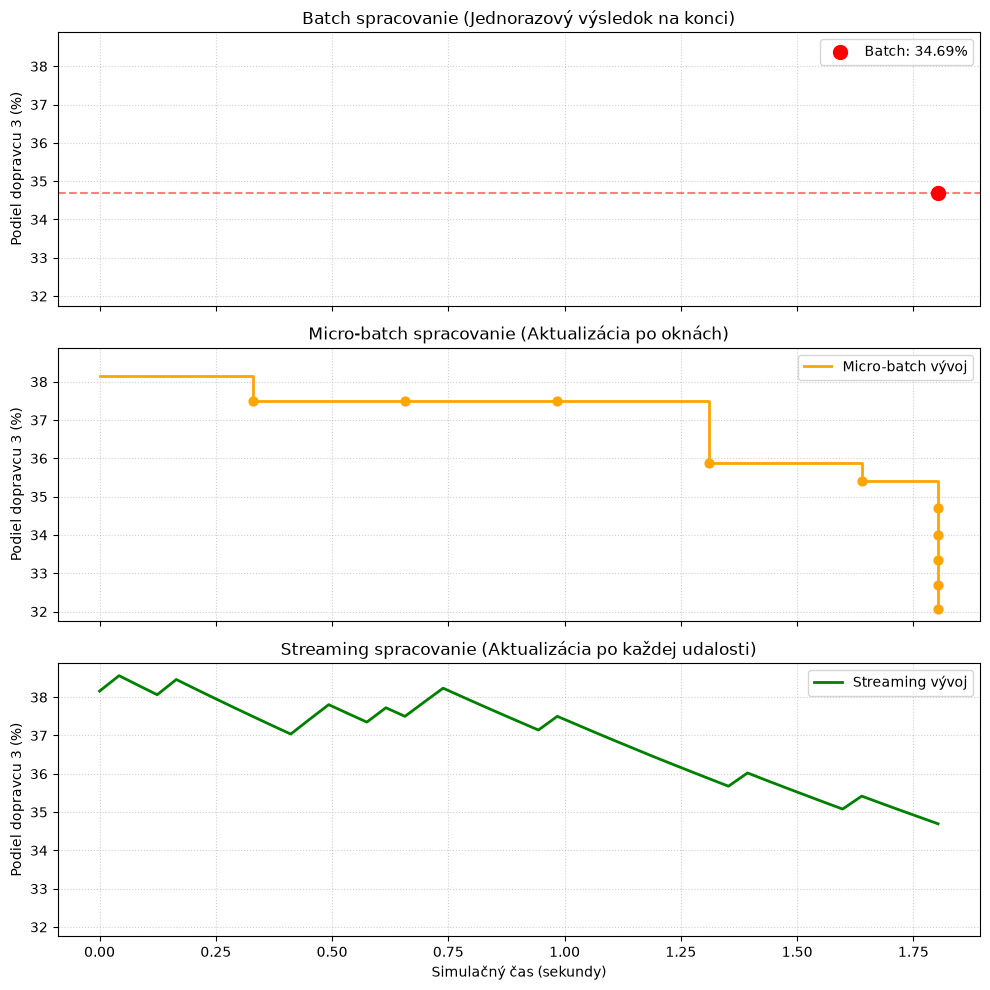

In [17]:
# Vaše riešenie
import matplotlib.pyplot as plt

stream_times = [pt[0] for pt in streaming_history]
stream_pcts = [pt[2] for pt in streaming_history]

micro_times = [pt[0] for pt in micro_history]
micro_pcts = [pt[2] for pt in micro_history]

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 10), sharex=True, sharey=True)

final_time = stream_times[-1] if stream_times else 0.0
ax1.scatter(final_time, batch_pct, color='red', s=100, zorder=5, label=f"Batch: {batch_pct:.2f}%")
ax1.axhline(batch_pct, color='red', linestyle='--', alpha=0.5)
ax1.set_title("Batch spracovanie (Jednorazový výsledok na konci)")
ax1.set_ylabel("Podiel dopravcu 3 (%)")
ax1.legend(loc="upper right")
ax1.grid(True, linestyle=':', alpha=0.6)

historical_pct = (historical_orders['shipperid'] == 3).sum() / len(historical_orders) * 100
adjusted_micro_times = [0.0] + micro_times
adjusted_micro_pcts = [historical_pct] + micro_pcts

ax2.step(adjusted_micro_times, adjusted_micro_pcts, where="post", color='orange', linewidth=2, label="Micro-batch vývoj")
ax2.scatter(micro_times, micro_pcts, color='orange', s=40, zorder=3)
ax2.set_title("Micro-batch spracovanie (Aktualizácia po oknách)")
ax2.set_ylabel("Podiel dopravcu 3 (%)")
ax2.legend(loc="upper right")
ax2.grid(True, linestyle=':', alpha=0.6)

adjusted_stream_times = [0.0] + stream_times
adjusted_stream_pcts = [historical_pct] + stream_pcts

ax3.plot(adjusted_stream_times, adjusted_stream_pcts, color='green', linewidth=2, label="Streaming vývoj")
ax3.set_title("Streaming spracovanie (Aktualizácia po každej udalosti)")
ax3.set_xlabel("Simulačný čas (sekundy)")
ax3.set_ylabel("Podiel dopravcu 3 (%)")
ax3.legend(loc="upper right")
ax3.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 8 – Frekvencia aktualizácií a prvý výsledok</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Na troch grafoch znázornite, koľkokrát sa priebežný výsledok aktualizoval. Potom vytvorte jednoduchú tabuľku, ktorá porovná <strong>čas prvého výsledku</strong>.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Pri počte aktualizácií nie je vhodné zdieľať os Y: batch má jeden výsledok, streaming jeden po každej udalosti. Os X zdieľajte.</div>

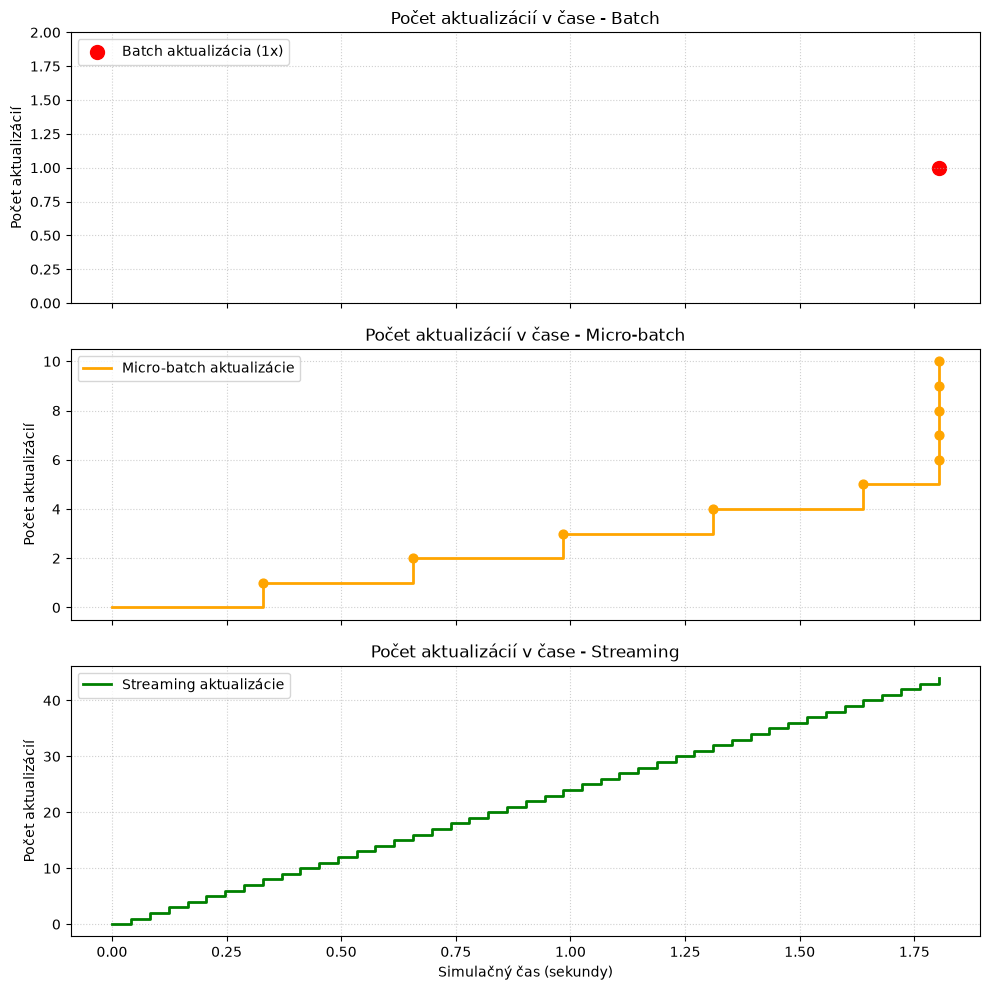


Porovnanie prístupov:


,Prístup,Prvý výsledok (s),Celkový počet aktualizácií
0,Batch,1.803,1
1,Micro-batch,0.329,10
2,Event streaming,0.042,44


In [18]:
# Vaše riešenie
import pandas as pd
import matplotlib.pyplot as plt

stream_times = [pt[0] for pt in streaming_history]
stream_updates = list(range(1, len(stream_times) + 1))

micro_times = [pt[0] for pt in micro_history]
micro_updates = list(range(1, len(micro_times) + 1))

final_time = stream_times[-1] if stream_times else 0.0
batch_times = [final_time]
batch_updates = [1]

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

ax1.scatter(batch_times, batch_updates, color='red', s=100, label="Batch aktualizácia (1x)")
ax1.set_title("Počet aktualizácií v čase - Batch")
ax1.set_ylabel("Počet aktualizácií")
ax1.set_ylim(0, 2)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc="upper left")

ax2.step([0.0] + micro_times, [0] + micro_updates, where="post", color='orange', linewidth=2, label="Micro-batch aktualizácie")
ax2.scatter(micro_times, micro_updates, color='orange', s=40, zorder=3)
ax2.set_title("Počet aktualizácií v čase - Micro-batch")
ax2.set_ylabel("Počet aktualizácií")
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc="upper left")

ax3.step([0.0] + stream_times, [0] + stream_updates, where="post", color='green', linewidth=2, label="Streaming aktualizácie")
ax3.set_title("Počet aktualizácií v čase - Streaming")
ax3.set_xlabel("Simulačný čas (sekundy)")
ax3.set_ylabel("Počet aktualizácií")
ax3.grid(True, linestyle=':', alpha=0.6)
ax3.legend(loc="upper left")

plt.tight_layout()
plt.show()

batch_first_res = final_time

micro_first_res = micro_times[0] if micro_times else 0.0

stream_first_res = stream_times[0] if stream_times else 0.0

comparison_data = {
    "Prístup": ["Batch", "Micro-batch", "Event streaming"],
    "Prvý výsledok (s)": [f"{batch_first_res:.3f}", f"{micro_first_res:.3f}", f"{stream_first_res:.3f}"],
    "Celkový počet aktualizácií": [len(batch_updates), len(micro_updates), len(stream_updates)]
}

comparison_df = pd.DataFrame(comparison_data)
print("\nPorovnanie prístupov:")
display(comparison_df)

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">
  📘 Kontrola Git repozitára po 8. týždni
</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">
  Po dokončení všetkých úloh z 8. týždňa skontrolujte, či máte vo svojom Git
  repozitári vytvorenú samostatnú vetvu
  <span style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">week-08</span>
  a či sa v nej nachádza vypracovaný notebook vytvorený počas cvičenia.
</p>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">
  Obsah vetvy
  <span style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">week-08</span>
  by mal mať približne nasledujúcu štruktúru:
</p>
<pre style="background: #f9fafb; color: #111827; padding: 14px; border-radius: 7px; overflow: auto; font-size: 13px; line-height: 1.7; font-family: ui-monospace, SFMono-Regular, Menlo, monospace;">week-08
│
├── ratings.csv
├── orders.csv
│
├── batch_streaming.ipynb
└── batch_streaming_orders.ipynb
</pre>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #eab308; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">
  ⚠️ <strong>Kontrola GitHubu:</strong> Skontrolujte, či sa všetky uvedené súbory
  nachádzajú aj vo vzdialenom repozitári na GitHube. Ak ich vidíte iba lokálne
  vo VS Code, zmeny ešte neboli úspešne odoslané pomocou
  <strong>commit</strong> a <strong>push</strong>.
</div>